In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


# 1️⃣ Load Dataset & Basic Structure

In [2]:
import pandas as pd

# Load dataset
df = pd.read_csv('/content/drive/MyDrive/Assamese_Sentiment_Analysis/Data/Assamese_Movie_Review_Shuffled_8987.csv')

# First look
df.head()


,ID,Reviews,Sentiment
0,0,বোকা নাটক,negative
1,1,নাটকখন বৰ ধুনীয়া আছিল।,positive
2,2,এখন ভাল ঘৰ এনে হ'ব লাগে,positive
3,3,এইটো আশ্চৰ্যকৰ আছিল,positive
4,4,মই বহুদিন অপেক্ষা কৰি আছো........ অৱশেষত দেখিল...,positive


In [3]:
# Shape of dataset
df.shape


(8987, 3)

In [4]:
# Column names and types
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8987 entries, 0 to 8986
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   ID         8987 non-null   int64 
 1   Reviews    8987 non-null   object
 2   Sentiment  8987 non-null   object
dtypes: int64(1), object(2)
memory usage: 210.8+ KB


# 2️⃣ Dataset Summary Statistics

In [5]:
# General statistics
df.describe(include='all')


,ID,Reviews,Sentiment
count,8987.000000,8987,8987
unique,NaN,7843,3
top,NaN,বোকা নাটক,positive
freq,NaN,81,5677
mean,4493.000000,NaN,NaN
std,2594.467768,NaN,NaN
min,0.000000,NaN,NaN
25%,2246.500000,NaN,NaN
50%,4493.000000,NaN,NaN
75%,6739.500000,NaN,NaN


In [6]:
# Number of rows and columns
num_rows, num_cols = df.shape
print(f"Rows: {num_rows}, Columns: {num_cols}")


Rows: 8987, Columns: 3


# 3️⃣ Missing Values Analysis

In [7]:
# Missing values per column
df.isnull().sum()


,0
ID,0
Reviews,0
Sentiment,0


In [8]:
# Percentage of missing values
(df.isnull().mean() * 100).round(2)


,0
ID,0.0
Reviews,0.0
Sentiment,0.0


In [9]:
# Rows with any missing value
df[df.isnull().any(axis=1)]


,ID,Reviews,Sentiment


# 4️⃣ Duplicate Analysis

In [10]:
# Total duplicate rows
df.duplicated().sum()


np.int64(0)

In [11]:
# View duplicate texts
df[df.duplicated(subset=['Reviews'], keep=False)]


,ID,Reviews,Sentiment
0,0,বোকা নাটক,negative
1,1,নাটকখন বৰ ধুনীয়া আছিল।,positive
3,3,এইটো আশ্চৰ্যকৰ আছিল,positive
6,6,অতুলনীয় বছ,positive
9,9,এইখন এখন সুন্দৰ নাটক,positive
...,...,...,...
8941,8941,শ্বমীম ভাইৰ নাটক ভাল হ'ব,positive
8976,8976,এইটো বহুত ভাল আছিল,positive
8978,8978,এইটো বহুত ভাল হৈছে।,positive
8984,8984,নাটকখন বৰ ধুনীয়া আছিল,positive


# 5️⃣ Label (Sentiment) Distribution

In [12]:
# Count of each sentiment
df['Sentiment'].value_counts()


,count
Sentiment,
positive,5677
negative,3309
Sentiment,1


In [13]:
# Percentage distribution
df['Sentiment'].value_counts(normalize=True) * 100


,proportion
Sentiment,
positive,63.169022
negative,36.819851
Sentiment,0.011127


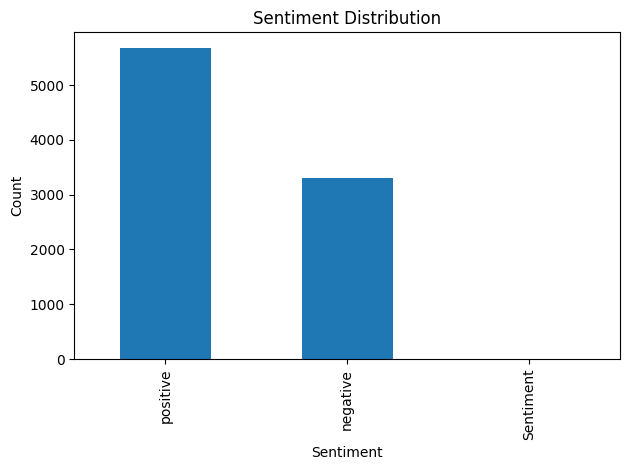

In [14]:
# Bar plot
import matplotlib.pyplot as plt

df['Sentiment'].value_counts().plot(kind='bar')
plt.title('Sentiment Distribution')
plt.xlabel('Sentiment')
plt.ylabel('Count')

plt.tight_layout()

save_path = "/content/drive/MyDrive/Assamese_Sentiment_Analysis/Results/class_imbalance"

# Save as vector graphics for publication
plt.savefig(f"{save_path}.svg", format="svg", dpi=300)

plt.show()

# 6️⃣ Language Verification (Ensure Assamese Only)

In [15]:
!pip install langdetect


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 981.5/981.5 kB 55.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for langdetect: filename=langdetect-1.0.9-py3-none-any.whl size=993223 sha256=553884e05418e41c7d9cc4606e0611a704fe5e5fba711b5de2b5d02dd67175ae
  Stored in directory: /root/.cache/pip/wheels/c1/67/88/e844b5b022812e15a52e4eaa38a1e709e99f06f6639d7e3ba7
Successfully built langdetect


In [16]:
from langdetect import detect

def detect_lang(text):
    try:
        return detect(text)
    except:
        return 'error'

df['language'] = df['Reviews'].apply(detect_lang)
df['language'].value_counts()


,count
language,
bn,8978
en,3
tr,1
tl,1
vi,1
af,1
error,1
ro,1


# Assamese may appear as 'bn' or 'as' depending on detector quality.

# 7️⃣ Text Length Analysis

In [18]:
#Character Length

df['char_len'] = df['Reviews'].astype(str).apply(len)
df['char_len'].describe()


,char_len
count,8987.000000
mean,64.187271
std,71.892051
min,1.000000
25%,24.000000
50%,43.000000
75%,79.000000
max,1412.000000


In [19]:
#Word Length

df['word_len'] = df['Reviews'].astype(str).apply(lambda x: len(x.split()))
df['word_len'].describe()


,word_len
count,8987.000000
mean,10.722377
std,11.798452
min,1.000000
25%,4.000000
50%,7.000000
75%,13.000000
max,224.000000


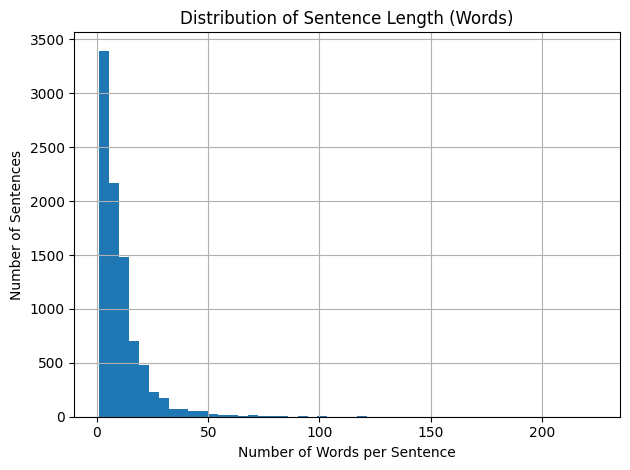

In [20]:
df['word_len'].hist(bins=50)
plt.xlabel('Number of Words per Sentence')
plt.ylabel('Number of Sentences')
plt.title('Distribution of Sentence Length (Words)')

plt.tight_layout()

save_path = "/content/drive/MyDrive/Assamese_Sentiment_Analysis/Results/distribution_plot"

# Save as vector graphics for publication
plt.savefig(f"{save_path}.svg", format="svg", dpi=300)

plt.show()


# 8️⃣ Sentence Length by Sentiment

In [21]:
df.groupby('Sentiment')['word_len'].mean()


,word_len
Sentiment,
Sentiment,1.000000
negative,11.290118
positive,10.393165


In [22]:
df.groupby('Sentiment')['char_len'].mean()


,char_len
Sentiment,
Sentiment,7.000000
negative,67.778181
positive,62.104280


# 9️⃣ Unique Vocabulary Analysis (Assamese)

In [23]:
# Tokenize words
all_words = ' '.join(df['Reviews'].astype(str)).split()

# Unique words
unique_words = set(all_words)
print("Total words:", len(all_words))
print("Unique words:", len(unique_words))


Total words: 96362
Unique words: 12824


In [24]:
# Vocabulary richness
len(unique_words) / len(all_words)


0.13308150515763476

# 🔟 Most Frequent Words

In [25]:
from collections import Counter

word_freq = Counter(all_words)
word_freq.most_common(30)


[('ভাল', 2930),
 ('মই', 2923),
 ('নাটক', 2397),
 ('আৰু', 1714),
 ('নাটকখন', 988),
 ('এখন', 940),
 ('এই', 865),
 ('মোৰ', 858),
 ('এইটো', 813),
 ('বহুত', 789),
 ('এটা', 772),
 ('বৰ', 764),
 ('সুন্দৰ', 722),
 ('বাবে', 641),
 ('আপুনি', 633),
 ('ইমান', 572),
 ('নিশো', 567),
 ('এক', 553),
 ('ধুনীয়া', 531),
 ('এইখন', 518),
 ('শ্ৰেষ্ঠ', 497),
 ('নাটকৰ', 476),
 ('নাটক।', 453),
 ('যে', 445),
 ('কিন্তু', 436),
 ('এনে', 434),
 ('সঁচাকৈয়ে', 408),
 ('ভাই', 403),
 ('বেয়া', 402),
 ('ই', 399)]

# 1️⃣1️⃣ Assamese Stopword Analysis

In [26]:
assamese_stopwords = [
    'আৰু','এই','সেই','হয়','আমি','তুমি','তেওঁ','মই','এটা','এনে'
]

df['stopword_count'] = df['Reviews'].apply(
    lambda x: sum(1 for w in x.split() if w in assamese_stopwords)
)

df['stopword_count'].describe()


,stopword_count
count,8987.000000
mean,0.812396
std,1.367556
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,20.000000


# 1️⃣2️⃣ Emoji, Symbol & Punctuation Analysis

In [27]:
import re

def count_emojis(Reviews):
    emoji_pattern = re.compile("["
        u"\U0001F600-\U0001F64F"
        u"\U0001F300-\U0001F5FF"
        u"\U0001F680-\U0001F6FF"
        u"\U0001F1E0-\U0001F1FF"
        "]+", flags=re.UNICODE)
    return len(emoji_pattern.findall(Reviews))

df['emoji_count'] = df['Reviews'].apply(count_emojis)
df['emoji_count'].describe()


,emoji_count
count,8987.000000
mean,0.010126
std,0.116556
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,4.000000


In [28]:
# Punctuation count
df['punct_count'] = df['Reviews'].str.count(r'[!?,.]')
df['punct_count'].describe()


,punct_count
count,8987.000000
mean,1.465561
std,3.149585
min,0.000000
25%,0.000000
50%,0.000000
75%,2.000000
max,129.000000


# 1️⃣3️⃣ Special Character & Number Analysis

In [29]:
#Number Analysis

df['num_count'] = df['Reviews'].str.count(r'\d')
df['num_count'].describe()

,num_count
count,8987.000000
mean,0.107155
std,0.661811
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,19.000000


In [30]:
#Special Character Analysis

df['special_char_count'] = df['Reviews'].str.count(r'[@#$%^&*]')
df['special_char_count'].describe()

,special_char_count
count,8987.000000
mean,0.014132
std,0.178154
min,0.000000
25%,0.000000
50%,0.000000
75%,0.000000
max,8.000000


# 1️⃣4️⃣ Sentence Polarity Leakage Check (Manual Heuristic)

In [31]:
positive_words = ['ভাল', 'শ্ৰেষ্ঠ', 'উত্তম']
negative_words = ['বেয়া', 'খাৰাপ', 'নষ্ট']

def polarity_hint(Reviews):
    pos = sum(w in Reviews for w in positive_words)
    neg = sum(w in Reviews for w in negative_words)
    return pos, neg

df[['pos_hint','neg_hint']] = df['Reviews'].apply(
    lambda x: pd.Series(polarity_hint(x))
)


In [32]:
#How many samples contain polarity hints?
(df['pos_hint'] > 0).sum(), (df['neg_hint'] > 0).sum()


(np.int64(3326), np.int64(510))

In [33]:
#Percentage of dataset with explicit sentiment words
((df['pos_hint'] + df['neg_hint']) > 0).mean() * 100


np.float64(41.80482919773005)

Interpretation

< 20% → low leakage (good)

20–40% → moderate leakage

> 40% → high leakage ⚠️

In [34]:
#Show Leakage by Label
pd.crosstab(df['Sentiment'], df['pos_hint'] > 0)


pos_hint,False,True
Sentiment,,
Sentiment,1,0
negative,2839,470
positive,2821,2856


In [35]:
pd.crosstab(df['Sentiment'], df['neg_hint'] > 0)


neg_hint,False,True
Sentiment,,
Sentiment,1,0
negative,2829,480
positive,5647,30


# 1️⃣5️⃣ Label vs Keyword Correlation

In [36]:
pd.crosstab(df['Sentiment'], df['pos_hint'] > 0)


pos_hint,False,True
Sentiment,,
Sentiment,1,0
negative,2839,470
positive,2821,2856


# 1️⃣6️⃣ Outlier Detection (Very Long / Very Short Text)

In [37]:
# Extremely short sentences
df[df['word_len'] <= 2]


,ID,Reviews,Sentiment,language,char_len,word_len,stopword_count,emoji_count,punct_count,num_count,special_char_count,pos_hint,neg_hint
0,0,বোকা নাটক,negative,bn,11,2,0,0,0,0,0,0,0
6,6,অতুলনীয় বছ,positive,bn,11,2,0,0,0,0,0,0,0
30,30,ভুৱা নাটক,negative,bn,11,2,0,0,0,0,0,0,0
55,55,অতিৰঞ্জিত ভাড়াতীয়া।,negative,bn,23,2,0,0,0,0,0,0,0
57,57,অপূৰ্ব বছ,positive,bn,9,2,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8907,8907,মূৰ্খ মূৰ্খ,negative,bn,11,2,0,0,0,0,0,0,0
8915,8915,বোকা নাটক,negative,bn,11,2,0,0,0,0,0,0,0
8953,8953,আজাইৰা।,negative,bn,7,1,0,0,0,0,0,0,0
8968,8968,কি সুন্দৰ,positive,bn,9,2,0,0,0,0,0,0,0


In [38]:
# Extremely long sentences
df[df['word_len'] > df['word_len'].quantile(0.99)]


,ID,Reviews,Sentiment,language,char_len,word_len,stopword_count,emoji_count,punct_count,num_count,special_char_count,pos_hint,neg_hint
56,56,"সঁচা কথা ক'বলৈ গ'লে, বাংলাদেশত এনে নাটক চোৱাৰ ...",positive,bn,338,57,8,0,4,0,0,1,0
163,163,"লেতেৰা, অশ্লীলতা আৰু অশ্লীলতাৰ উপৰিও, এতিয়াও ...",positive,bn,360,64,3,0,7,0,0,2,0
204,204,কাহিনীটোত কোনো ভুল নাই। এয়া সম্পূৰ্ণ ভাড়াৰ ব...,negative,bn,578,98,4,0,4,0,0,1,1
243,243,নাটকখনত সকলো ঠিকেই আছে। কিন্তু নাটকৰ নায়িকীৰ ...,negative,bn,422,66,2,0,9,0,0,0,0
276,276,নাটকৰ এই দৃশ্যবোৰ অতি দুখজনক আছচালামু আলাইকুমে...,negative,bn,445,76,7,0,10,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
8252,8252,"অৱশ্যে, নাটকখন চাই আমি বহুত শিকিব লগা আছে, কিন...",negative,bn,882,147,5,0,12,7,0,0,1
8409,8409,"সোনকাল কৰা, ভাই! মনোযোগ দিয়ক, অনুগ্ৰহ কৰি মোক...",negative,bn,946,163,14,0,20,0,0,1,0
8640,8640,"এক কথাত ক'বলৈ গ'লে, মহান নাটক। এয়াই প্ৰথমবাৰৰ...",positive,bn,331,62,9,0,2,0,0,1,0
8664,8664,"মই ভাৰতৰ পৰা কৈছোঁ, মই বাংলাদেশৰ পৰা বহুতো চিন...",positive,bn,408,68,6,0,1,0,0,0,0


# 1️⃣7️⃣ Noise Detection (Repeated Characters)

In [39]:
df['repeated_char'] = df['Reviews'].str.contains(r'(.)\1{3,}')
df['repeated_char'].value_counts()


/tmp/ipykernel_407/1020110920.py:1: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df['repeated_char'] = df['Reviews'].str.contains(r'(.)\1{3,}')


,count
repeated_char,
False,8440
True,547


# 1️⃣8️⃣ Sentiment-wise Vocabulary

In [40]:
df.groupby('Sentiment')['Reviews'].apply(
    lambda x: Counter(' '.join(x).split()).most_common(10)
)


,Reviews
Sentiment,
Sentiment,"[(Reviews, 1)]"
negative,"[(নাটক, 1030), (মই, 777), (আৰু, 642), (ভাল, 49..."
positive,"[(ভাল, 2433), (মই, 2146), (নাটক, 1367), (আৰু, ..."


# 1️⃣9️⃣ Dataset Bias Check

In [42]:
# Avg sentence length per label
df.groupby('Sentiment')['word_len'].mean()


,word_len
Sentiment,
Sentiment,1.000000
negative,11.290118
positive,10.393165


# 2️⃣0️⃣ Export Full Dataset Report

In [ ]:
df.to_csv('/content/drive/MyDrive/Assamese_Sentiment_Analysis/Results/Assamese_Dataset_details.csv', index=False)
